# Task 1: Data Acquisition, Cleaning, and Preprocessing

Internship: Virtual Data Science with Python Trainee
Platform: YuvaIntern

Objective:
To acquire a public dataset, inspect its quality, identify missing
values, duplicates, invalid values and potential outliers, and
prepare a documented dataset for further analysis.

Dataset: Online Retail
Source: UCI Machine Learning Repository

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "datasets"
OUTPUT_DIR = PROJECT_DIR / "outputs"

print("Project folder:", PROJECT_DIR)
print("Dataset folder:", DATA_DIR)
print("Output folder:", OUTPUT_DIR)

print("Excel files found:")
for file in DATA_DIR.glob("*.xlsx"):
    print(file.name)

Project folder: C:\Users\Ayush\YuvaIntern_Data_Science
Dataset folder: C:\Users\Ayush\YuvaIntern_Data_Science\datasets
Output folder: C:\Users\Ayush\YuvaIntern_Data_Science\outputs
Excel files found:
Online Retail.xlsx


In [ ]:
# Step 2: Load the dataset

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "datasets"

# Show available Excel files
excel_files = list(DATA_DIR.glob("*.xlsx"))

print("Excel files found:", [file.name for file in excel_files])

Excel files found: ['Online Retail.xlsx']


In [ ]:
# Load the Excel dataset

if not excel_files:
    raise FileNotFoundError(
        f"No Excel file found in: {DATA_DIR}"
    )

file_path = excel_files[0]
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("File name:", file_path.name)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
File name: Online Retail.xlsx
Number of rows: 541909
Number of columns: 8


In [ ]:
# Display the first 5 rows

display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Check column names and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
# Step 4: Check missing values

missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

display(missing_report.sort_values(
    by="Missing Count",
    ascending=False
))

,Missing Count,Missing Percentage (%)
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


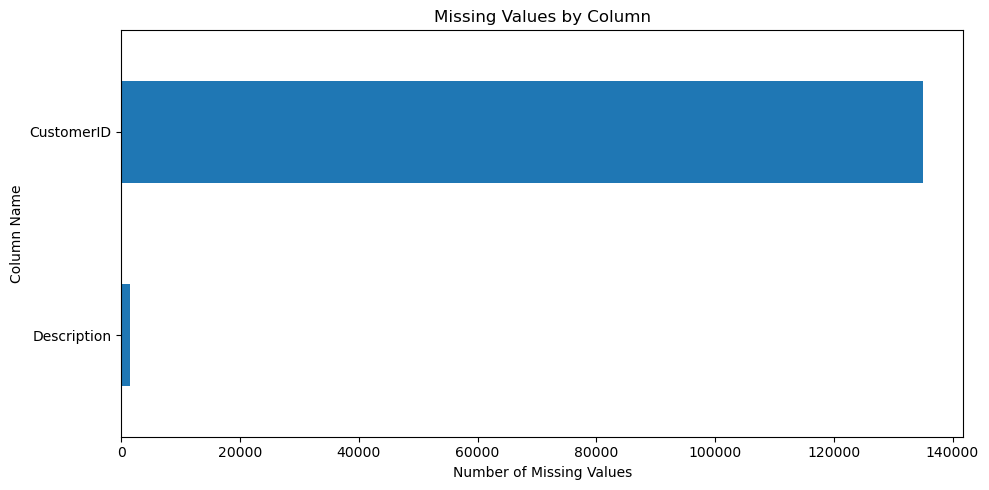

In [ ]:
import matplotlib.pyplot as plt

missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

if len(missing_counts) > 0:
    missing_counts.sort_values().plot(
        kind="barh",
        figsize=(10, 5)
    )
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column Name")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

In [ ]:
# Step 6: Detect duplicate records

duplicate_count = df.duplicated().sum()

print("Total rows in original dataset:", len(df))
print("Duplicate rows found:", duplicate_count)

Total rows in original dataset: 541909
Duplicate rows found: 5268


In [ ]:
# Display duplicate records

duplicate_rows = df[df.duplicated(keep=False)]

print("Total duplicate-related rows:", len(duplicate_rows))
display(duplicate_rows.head(10))

Total duplicate-related rows: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [ ]:
# Remove exact duplicate rows

df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Original rows: 541909
Rows after removing duplicates: 536641
Duplicate rows removed: 5268
Remaining duplicate rows: 0


In [ ]:
# Step 9: Check suspicious values

print("Column names:")
print(df_clean.columns.tolist())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [ ]:
# Check Quantity and UnitPrice

required_columns = ["Quantity", "UnitPrice"]

if all(col in df_clean.columns for col in required_columns):

    print("Quantity less than or equal to zero:")
    display(df_clean[df_clean["Quantity"] <= 0].head(10))

    print("UnitPrice less than or equal to zero:")
    display(df_clean[df_clean["UnitPrice"] <= 0].head(10))

    print("Quantity summary:")
    display(df_clean["Quantity"].describe())

    print("UnitPrice summary:")
    display(df_clean["UnitPrice"].describe())

else:
    print("Quantity or UnitPrice column is missing.")
    print("Please check the column names printed above.")

Quantity less than or equal to zero:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


UnitPrice less than or equal to zero:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


Quantity summary:


count    536641.000000
mean          9.620029
std         219.130156
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

UnitPrice summary:


count    536641.000000
mean          4.632656
std          97.233118
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [ ]:
# Count suspicious records

if all(col in df_clean.columns for col in ["Quantity", "UnitPrice"]):

    nonpositive_quantity = (df_clean["Quantity"] <= 0).sum()
    nonpositive_price = (df_clean["UnitPrice"] <= 0).sum()

    print("Non-positive Quantity records:", nonpositive_quantity)
    print("Non-positive UnitPrice records:", nonpositive_price)

    print(
        "Records where Quantity and UnitPrice are both non-positive:",
        ((df_clean["Quantity"] <= 0) &
         (df_clean["UnitPrice"] <= 0)).sum()
    )

Non-positive Quantity records: 10587
Non-positive UnitPrice records: 2512
Records where Quantity and UnitPrice are both non-positive: 1336


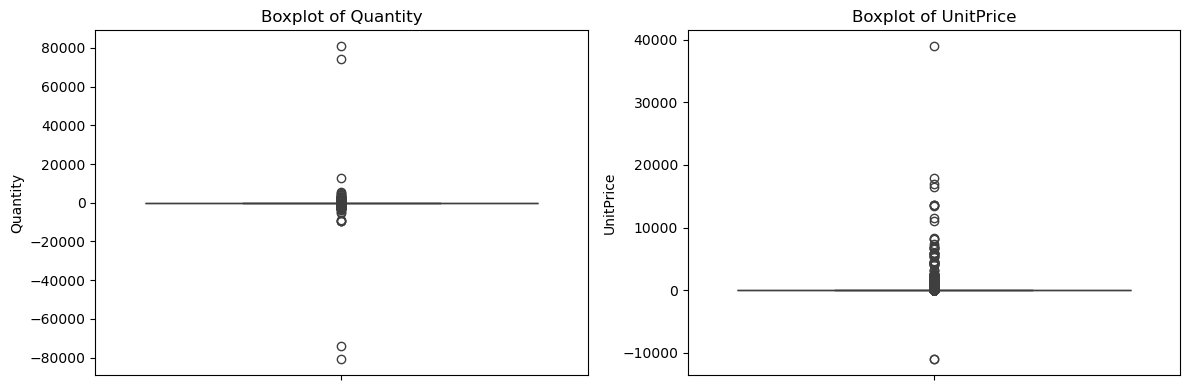

In [ ]:

# Step 11: Outlier detection

import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    col for col in ["Quantity", "UnitPrice"]
    if col in df_clean.columns
]

if numeric_columns:
    fig, axes = plt.subplots(
        1, len(numeric_columns),
        figsize=(6 * len(numeric_columns), 4)
    )

    if len(numeric_columns) == 1:
        axes = [axes]

    for ax, col in zip(axes, numeric_columns):
        sns.boxplot(y=df_clean[col], ax=ax)
        ax.set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()
else:
    print("No expected numerical columns found.")


In [ ]:

# Calculate IQR-based outliers

def iqr_outlier_info(series):
    series = pd.to_numeric(series, errors="coerce").dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (series < lower_bound) |
        (series > upper_bound)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outliers.sum())
    }

for col in numeric_columns:
    print(f"\n{col}")
    print(iqr_outlier_info(df_clean[col]))



Quantity
{'Q1': np.float64(1.0), 'Q3': np.float64(10.0), 'IQR': np.float64(9.0), 'Lower Bound': np.float64(-12.5), 'Upper Bound': np.float64(23.5), 'Outlier Count': 58501}

UnitPrice
{'Q1': np.float64(1.25), 'Q3': np.float64(4.13), 'IQR': np.float64(2.88), 'Lower Bound': np.float64(-3.0700000000000003), 'Upper Bound': np.float64(8.45), 'Outlier Count': 39450}


In [ ]:

# Step 12: Correct data types

if "InvoiceDate" in df_clean.columns:
    df_clean["InvoiceDate"] = pd.to_datetime(
        df_clean["InvoiceDate"],
        errors="coerce"
    )
    print(
        "Invalid or missing dates:",
        df_clean["InvoiceDate"].isna().sum()
    )

for col in ["Quantity", "UnitPrice"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col],
            errors="coerce"
        )

print("\nUpdated data types:")
print(df_clean.dtypes)


Invalid or missing dates: 0

Updated data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:

# Step 13: Recheck missing values

final_missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage (%)": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

display(
    final_missing_report.sort_values(
        by="Missing Count",
        ascending=False
    )
)


,Missing Count,Missing Percentage (%)
CustomerID,135037,25.16
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [ ]:

# Step 14: Final validation

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate rows remaining:", df_clean.duplicated().sum())
print("Total missing cells:", df_clean.isnull().sum().sum())

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst five cleaned rows:")
display(df_clean.head())


Original dataset shape: (541909, 8)
Cleaned dataset shape: (536641, 8)
Duplicate rows remaining: 0
Total missing cells: 136491

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

First five cleaned rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Step 15: Create a cleaning summary

summary_data = [
    ("Original row count", len(df)),
    ("Original column count", len(df.columns)),
    ("Duplicate rows in original dataset", int(df.duplicated().sum())),
    ("Rows after duplicate removal", len(df_clean)),
    ("Exact duplicate rows removed", len(df) - len(df_clean)),
    ("Missing cells in original dataset", int(df.isnull().sum().sum())),
    ("Missing cells in cleaned dataset", int(df_clean.isnull().sum().sum()))
]

if "Quantity" in df_clean.columns:
    summary_data.append((
        "Non-positive Quantity records",
        int((df_clean["Quantity"] <= 0).sum())
    ))

if "UnitPrice" in df_clean.columns:
    summary_data.append((
        "Non-positive UnitPrice records",
        int((df_clean["UnitPrice"] <= 0).sum())
    ))

cleaning_summary = pd.DataFrame(
    summary_data,
    columns=["Metric", "Value"]
)

display(cleaning_summary)


,Metric,Value
0,Original row count,541909
1,Original column count,8
2,Duplicate rows in original dataset,5268
3,Rows after duplicate removal,536641
4,Exact duplicate rows removed,5268
5,Missing cells in original dataset,136534
6,Missing cells in cleaned dataset,136491
7,Non-positive Quantity records,10587
8,Non-positive UnitPrice records,2512


In [ ]:

# Step 16: Save output files

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cleaned_file = OUTPUT_DIR / "online_retail_cleaned.csv"
summary_file = OUTPUT_DIR / "task1_cleaning_summary.csv"
missing_file = OUTPUT_DIR / "task1_missing_values_report.csv"

df_clean.to_csv(cleaned_file, index=False)
cleaning_summary.to_csv(summary_file, index=False)
final_missing_report.to_csv(missing_file)

print("Files saved successfully:")
print(cleaned_file)
print(summary_file)
print(missing_file)

print("\nFile existence check:")
print("Cleaned data:", cleaned_file.exists())
print("Cleaning summary:", summary_file.exists())
print("Missing values report:", missing_file.exists())


Files saved successfully:
C:\Users\Ayush\YuvaIntern_Data_Science\outputs\online_retail_cleaned.csv
C:\Users\Ayush\YuvaIntern_Data_Science\outputs\task1_cleaning_summary.csv
C:\Users\Ayush\YuvaIntern_Data_Science\outputs\task1_missing_values_report.csv

File existence check:
Cleaned data: True
Cleaning summary: True
Missing values report: True
